# Лабораторная работа 2. Кластеризация городов методом k-средних

**Тема:** экономика городов.

Данные те же, что в первой лабораторной. Там я строил иерархию методом Уорда и остановился на четырех группах. Здесь разбиваю города методом k-средних, отдельно выбираю число кластеров и сверяю новое разбиение со старым.


## 1. Описание данных

Данные описывают экономические условия в 48 городах мира в 1991 году. Их собрал отдел экономических исследований банка Union (Швейцария).

- **Файл:** `data/Econom_Cities_data.csv` (разделитель `;`, десятичная запятая)
- **Число наблюдений:** 48

| Переменная | Название | Описание |
|---|---|---|
| `City` | Город | Название города |
| `Work` | Работа | Взвешенное среднее числа рабочих часов по 12 профессиям |
| `Price` | Цена | Индекс цен 112 товаров и услуг, включая аренду жилья (для Цюриха взято 100) |
| `Salary` | Заработная плата | Индекс часовой зарплаты по 12 профессиям после налогов и вычетов (для Цюриха взято 100) |


## 2. Постановка задачи

Разбить города на группы с похожими условиями по признакам `Work`, `Price` и `Salary`. Число групп заранее не задано: его нужно выбрать и объяснить. Потом описать, чем группы отличаются, и сравнить их с четырьмя кластерами из первой работы.


## 3. Этапы решения

1. Загрузка и проверка данных.
2. Обработка пропусков.
3. Короткий разведочный анализ.
4. Стандартизация признаков.
5. Как устроен метод k-средних, на двух признаках.
6. Зависимость результата от начальных центров.
7. Выбор числа кластеров.
8. Итоговое разбиение и описание групп.
9. Сравнение с иерархическим анализом.
10. Выводы.


## Окружение и библиотеки


In [1]:
import os

os.environ['LOKY_MAX_CPU_COUNT'] = '2'

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


## Этап 1. Загрузка и проверка данных

Столбцы разделены `;`, дробная часть записана через запятую.


In [2]:
DATA_PATH = Path('../data/Econom_Cities_data.csv')

df = pd.read_csv(DATA_PATH, sep=';', decimal=',')
df.head()


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [3]:
print('Размер таблицы:', df.shape)
print('Повторяющихся названий городов:', int(df['City'].duplicated().sum()))

df.dtypes


Размер таблицы: (48, 4)
Повторяющихся названий городов: 0


City       object
Work        int64
Price     float64
Salary    float64
dtype: object

## Этап 2. Обработка пропусков

В файле пропуск записан числом `-9999`, а не пустой ячейкой. Найду такие строки.


In [4]:
numeric_columns = ['Work', 'Price', 'Salary']

missing_rows = df[numeric_columns].eq(-9999).any(axis=1)
df.loc[missing_rows]


,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


У Cairo и Jakarta заполнен только `Price`. Подставлять среднее сразу в два признака из трех нельзя: город окажется рядом с «типичным» городом, хотя мы про него почти ничего не знаем. Эти две строки убираю, как и в первой работе.


In [5]:
df_with_nan = df.copy()
df_with_nan[numeric_columns] = df_with_nan[numeric_columns].replace(-9999, np.nan)

df_clean = df_with_nan.dropna(subset=numeric_columns).copy()
df_clean['Work'] = df_clean['Work'].astype(int)
df_clean = df_clean.set_index('City')

print('Было строк:', len(df), 'осталось:', len(df_clean))
df_clean.head()


Было строк: 48 осталось: 46


,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5
Bombay,2052,30.3,5.3
Brussels,1708,73.8,50.5


### Итог этапа 2

Дальше работаю с 46 городами. Пропусков в `df_clean` нет.


## Этап 3. Разведочный анализ

Подробный разбор уже был в первой работе. Здесь только то, что нужно для k-средних: масштаб признаков, связь между ними и заметные края распределения.


In [6]:
stats = df_clean[numeric_columns].describe().T
stats['skew'] = df_clean[numeric_columns].skew()
stats.round(2)


,count,mean,std,min,25%,50%,75%,max,skew
Work,46.0,1879.91,174.34,1583.0,1745.25,1849.00,1976.25,2375.0,0.77
Price,46.0,70.10,21.39,30.3,51.78,70.95,81.90,115.5,0.41
Salary,46.0,39.55,24.76,2.7,14.38,43.65,59.70,100.0,0.21


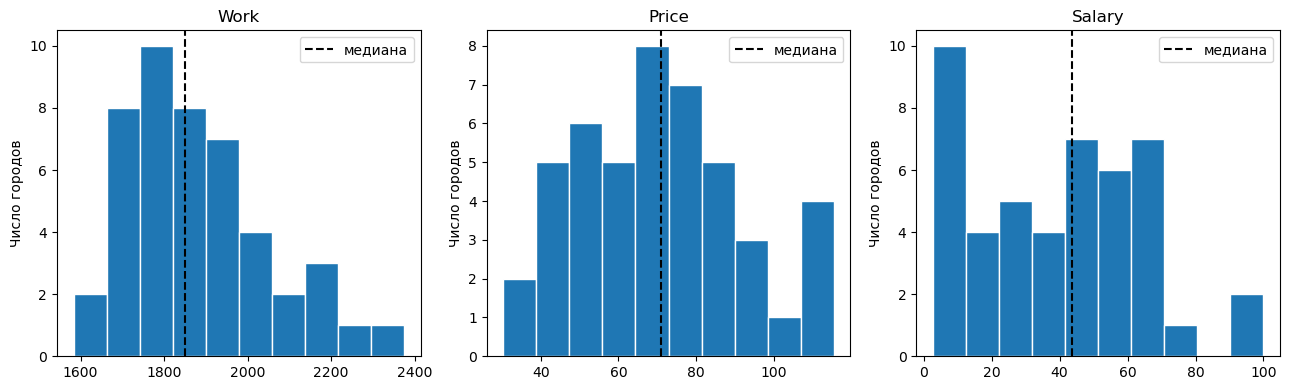

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, column in zip(axes, numeric_columns):
    ax.hist(df_clean[column], bins=10, edgecolor='white')
    ax.axvline(df_clean[column].median(), color='black', linestyle='--', label='медиана')
    ax.set_title(column)
    ax.set_ylabel('Число городов')
    ax.legend()

plt.tight_layout()
plt.show()


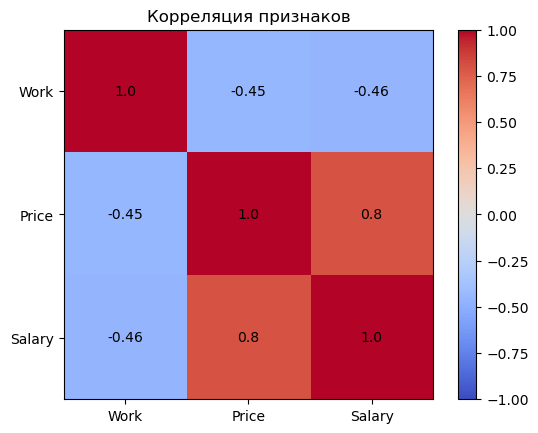

In [8]:
correlation = df_clean[numeric_columns].corr()

plt.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(3), numeric_columns)
plt.yticks(range(3), numeric_columns)

for i in range(3):
    for j in range(3):
        plt.text(j, i, round(correlation.iloc[i, j], 2), ha='center', va='center')

plt.title('Корреляция признаков')
plt.show()


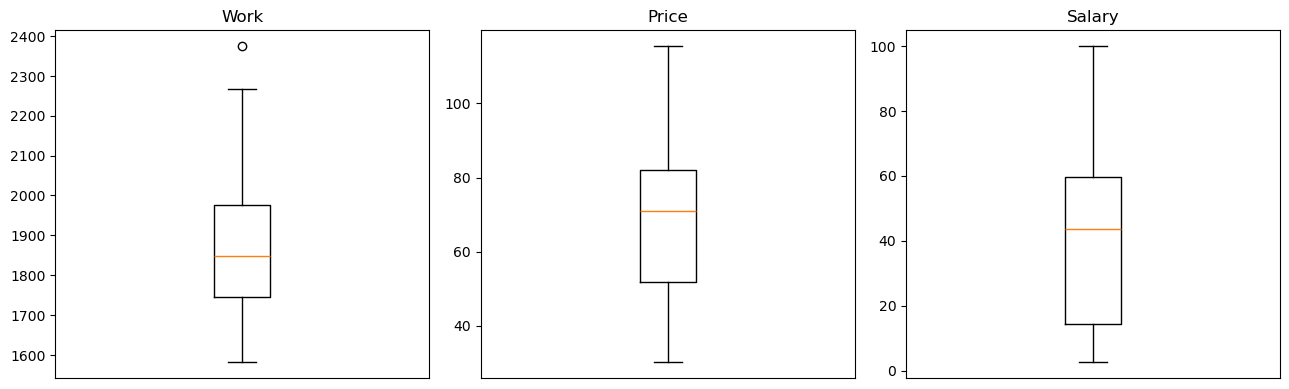

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, column in zip(axes, numeric_columns):
    ax.boxplot(df_clean[column])
    ax.set_title(column)
    ax.set_xticks([])

plt.tight_layout()
plt.show()


### Итог этапа 3

`Work` измеряется тысячами часов, `Price` и `Salary` это индексы около 30-100. Если считать расстояние по сырым числам, почти весь вклад даст `Work`. Перед k-средними признаки надо привести к одному масштабу.

`Price` и `Salary` связаны положительно: где дороже, там выше индекс зарплаты. С `Work` оба связаны отрицательно: где работают дольше, там в среднем ниже цены и зарплаты.

По `Work` в стороне стоит Hong Kong, это было видно и в первой работе. Строку не выкидываю: значение большое, но это не ошибка записи, а длинный рабочий день.


## Этап 4. Стандартизация признаков

Считаю z-оценки, как в лабораторной 1:

$$
z = \frac{x - \bar{x}}{s}.
$$

После этого единица по каждой оси равна одному стандартному отклонению, и евклидово расстояние больше не привязано к часам.


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df_clean[numeric_columns])

df_scaled = pd.DataFrame(X, columns=numeric_columns, index=df_clean.index)
df_scaled.head()


,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351


In [11]:
print('Средние:')
print(df_scaled.mean().round(3))
print()
print('Стандартные отклонения:')
print(df_scaled.std(ddof=0).round(3))


Средние:
Work      0.0
Price    -0.0
Salary    0.0
dtype: float64

Стандартные отклонения:
Work      1.0
Price     1.0
Salary    1.0
dtype: float64


### Итог этапа 4

Средние стали 0, стандартные отклонения 1. Дальше k-средние считаю по матрице `X`.


## Этап 5. Как работает метод k-средних

Нужно разложить объекты по `k` группам и поставить в каждой группе центр так, чтобы сумма квадратов расстояний до своего центра была маленькой:

$$
J = \sum_{j=1}^{k} \sum_{x \in C_j} \|x - \mu_j\|^2.
$$

Перебрать все разбиения нельзя, поэтому используют поочередную схему:

1. Выбрать `k` начальных центров.
2. Отнести каждый город к ближайшему центру.
3. Заменить центр средним значением городов, которые к нему попали.
4. Повторять шаги 2 и 3, пока состав групп не перестанет меняться.

На шаге 3 среднее подходит потому, что для уже собранной группы сумма квадратов минимальна именно в ее среднем. Пока группы пересчитываются, `J` не растет: каждый город либо остается, либо переходит к более близкому центру, а потом центр пододвигается к своим точкам.

Остановка не гарантирует самое лучшее разбиение. Из другой стартовой точки алгоритм может прийти в другую точку, где `J` тоже уже не уменьшается.

Еще одно свойство метода: город всегда достается ближайшему центру, то есть пространство режется на области вокруг центров. Так удобно ловить компактные группы. Вытянутую группу метод может разрезать на две только из-за того, что два центра встали вдоль нее.

Начальные центры беру схемой k-means++. Первый центр случайный, а каждый следующий чаще выбирается среди точек, которые далеко от уже взятых центров. Тогда стартовые центры не сваливаются в одно место.


Посмотрю шаги на самих городах, но только по `Price` и `Salary`, чтобы картинка была плоской. Стартовые центры ставлю в Bombay, Geneva и Manila. Bombay здесь крайняя точка с очень низкой зарплатой, Geneva наоборот с очень высокой, Manila где-то посередине по зарплате и с низкими ценами. Полный расчет ниже снова идет по всем трем признакам.


In [12]:
demo = df_scaled[['Price', 'Salary']].to_numpy()
start_cities = ['Bombay', 'Geneva', 'Manila']
start_idx = [df_scaled.index.get_loc(city) for city in start_cities]
centers = demo[start_idx].copy()

frames = []
for step in range(1, 16):
    dist = ((demo[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    labels_step = dist.argmin(axis=1)
    J_step = float(dist.min(axis=1).sum())
    sizes = [int((labels_step == j).sum()) for j in range(3)]
    frames.append((step, centers.copy(), labels_step.copy(), J_step, sizes))

    new_centers = np.vstack([demo[labels_step == j].mean(axis=0) for j in range(3)])
    if np.allclose(new_centers, centers):
        break
    centers = new_centers

for step, _, _, J_step, sizes in frames:
    print(f'шаг {step}: J = {J_step:.2f}, размеры групп {sizes}')


шаг 1: J = 89.53, размеры групп [1, 25, 20]
шаг 2: J = 26.44, размеры групп [3, 26, 17]
шаг 3: J = 25.50, размеры групп [6, 26, 14]
шаг 4: J = 24.64, размеры групп [9, 26, 11]
шаг 5: J = 24.16, размеры групп [10, 26, 10]
шаг 6: J = 24.12, размеры групп [10, 26, 10]


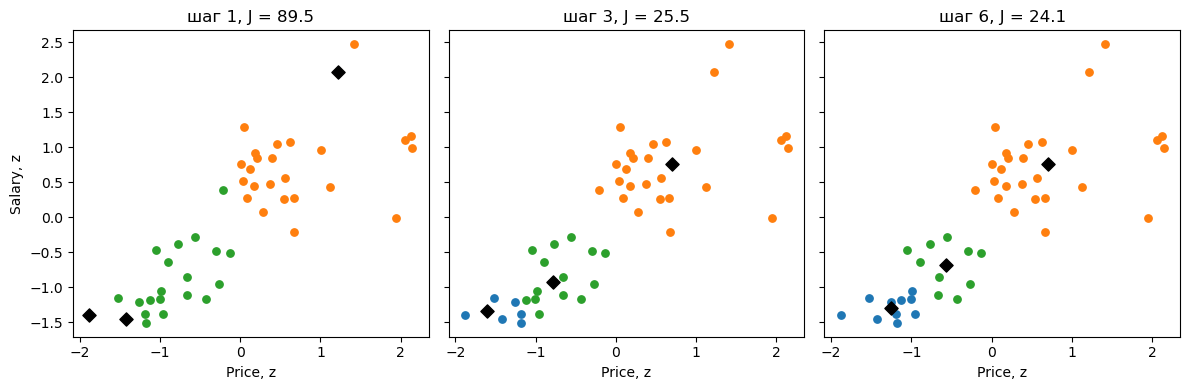

In [13]:
shown = [frames[0], frames[2], frames[-1]]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)

for ax, (step, centers_step, labels_step, J_step, _) in zip(axes, shown):
    for cluster in range(3):
        points = demo[labels_step == cluster]
        ax.scatter(points[:, 0], points[:, 1], s=28)
    ax.scatter(centers_step[:, 0], centers_step[:, 1], c='black', marker='D', s=45, zorder=3)
    ax.set_title(f'шаг {step}, J = {J_step:.1f}')
    ax.set_xlabel('Price, z')

axes[0].set_ylabel('Salary, z')
plt.tight_layout()
plt.show()


Черные ромбы на графике это центры. На первом шаге `J` около 90, и в группе Bombay только он сам: центр стоит на крае, остальные города ближе к Geneva или Manila. Потом этот центр сдвигается, группа растет до 10 городов, а `J` падает примерно до 24 и дальше не меняется. За шесть шагов алгоритм остановился.

Это учебный прогон по двум осям. Итоговое разбиение считаю по `Work`, `Price` и `Salary` вместе.


## Этап 6. Зависимость от начальных центров

Раз на демо уже видно, что путь зависит от старта, проверю это на полной задаче. Фиксирую `k = 4` и делаю 200 одиночных запусков с `n_init = 1`: отдельно со случайными центрами и отдельно с k-means++. `random_state` меняю, чтобы старты были разные.


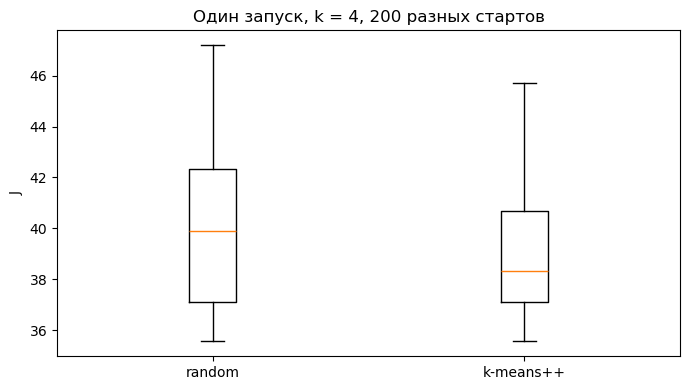

,минимум,медиана,среднее,доля лучших
Старт,,,,
k-means++,35.553,38.328,38.979,0.09
random,35.553,39.911,39.738,0.07


In [14]:
from sklearn.cluster import KMeans


def renumber_by_salary(raw_labels):
    # Номера KMeans ни к чему не привязаны. Нумерую группы по убыванию средней зарплаты.
    labels = pd.Series(np.asarray(raw_labels), index=df_clean.index)
    order = df_clean.groupby(labels)['Salary'].mean().sort_values(ascending=False).index
    return labels.map({old: new for new, old in enumerate(order, start=1)})


rows = []
for init in ('random', 'k-means++'):
    for seed in range(200):
        model_try = KMeans(n_clusters=4, init=init, n_init=1, random_state=seed)
        model_try.fit(X)
        rows.append({'Старт': init, 'J': model_try.inertia_})

runs = pd.DataFrame(rows)
best_J = runs['J'].min()

fig, ax = plt.subplots(figsize=(7, 4))
boxes = [runs.loc[runs['Старт'] == init, 'J'] for init in ('random', 'k-means++')]
ax.boxplot(boxes)
ax.set_xticks([1, 2], ['random', 'k-means++'])
ax.set_ylabel('J')
ax.set_title('Один запуск, k = 4, 200 разных стартов')
plt.tight_layout()
plt.show()

summary = runs.groupby('Старт')['J'].agg(минимум='min', медиана='median', среднее='mean')
summary['доля лучших'] = runs.groupby('Старт')['J'].apply(
    lambda values: np.mean(np.abs(values - best_J) < 0.01)
)
summary.round(3)


In [15]:
for init, group in runs.groupby('Старт'):
    p = np.mean(np.abs(group['J'] - best_J) < 0.01)
    chance = 1 - (1 - p) ** 50
    print(f'{init}: доля лучших запусков {p:.3f}, шанс поймать лучшее J за 50 попыток {chance:.3f}')


k-means++: доля лучших запусков 0.090, шанс поймать лучшее J за 50 попыток 0.991
random: доля лучших запусков 0.070, шанс поймать лучшее J за 50 попыток 0.973


Лучшее `J` одно и то же у обоих способов старта, около 35.55, но один запуск до него доходит редко: меньше чем в 10% случаев. У k-means++ медиана и среднее `J` ниже, то есть неудачные старты у него в среднем мягче, чем у совсем случайных центров. Все равно оставлять `n_init = 1` нельзя.

Если один запуск попадает в лучшее `J` с вероятностью `p`, то за 50 независимых запусков хотя бы один успех имеет вероятность `1 - (1 - p)^50`. Для k-means++ она близка к 1. Дальше так и ставлю: `init='k-means++'`, `n_init=50`, `random_state=0`, чтобы расчет можно было повторить.


Посмотрю, как выглядит неудачный старт. Беру один случайный запуск с `random_state=0` и сравниваю его с лучшим разбиением при тех же `k = 4`.


In [16]:
reference = KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=0).fit(X)
reference_labels = renumber_by_salary(reference.labels_)

bad = KMeans(n_clusters=4, init='random', n_init=1, random_state=0).fit(X)
bad_labels = renumber_by_salary(bad.labels_)

print('J лучшего разбиения:', round(reference.inertia_, 2))
print('J случайного старта:', round(bad.inertia_, 2))

bad_profile = df_clean.groupby(bad_labels)[numeric_columns].mean().round(2)
bad_profile['Городов'] = bad_labels.value_counts()
display(bad_profile)

pd.crosstab(reference_labels, bad_labels, rownames=['лучший'], colnames=['случайный старт'])


J лучшего разбиения: 35.55
J случайного старта: 44.23


,Work,Price,Salary,Городов
1,1789.24,84.97,59.03,25
2,1798.86,50.94,19.21,7
3,2142.56,56.82,17.28,9
4,1974.00,46.46,10.66,5


случайный старт,1,2,3,4
лучший,,,,
1,6,0,0,0
2,19,0,0,0
3,0,7,0,4
4,0,0,9,1


У случайного старта `J` около 44, это заметно хуже 35.55. По таблице сопряженности все города с высокой зарплатой, и шесть самых дорогих, и остальные девятнадцать, склеились в одну группу на 25 городов. Алгоритм остановился, но самое дорогое ядро от богатых городов так и не отделил. Отсюда и нужны повторные запуски: один старт может пропустить это деление.


## Этап 7. Выбор числа кластеров

`J` с ростом `k` почти всегда падает: больше центров, каждая точка в среднем ближе к своему. Поэтому маленький `J` сам по себе номер группы не выбирает. Смотрю, где падение замедляется, и рядом считаю средний силуэт. Силуэт уже использовал в первой работе: он около 1, если город ближе к своей группе, чем к чужим, и отрицательный, если его логичнее было бы отдать соседям.


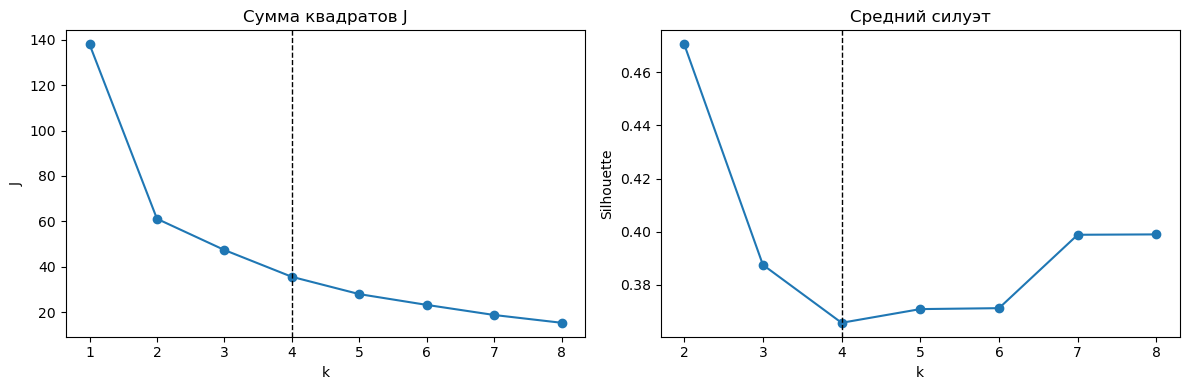

,J,Падение J,Silhouette
k,,,
1,138.00,NaN,NaN
2,61.12,76.88,0.470
3,47.36,13.76,0.388
4,35.55,11.81,0.366
5,27.93,7.62,0.371
6,23.18,4.75,0.371
7,18.73,4.45,0.399
8,15.30,3.43,0.399


In [17]:
from sklearn.metrics import silhouette_score

ks = list(range(1, 9))
inertias = []
silhouettes = []

for k in ks:
    model_k = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=0).fit(X)
    inertias.append(model_k.inertia_)
    if k == 1:
        silhouettes.append(np.nan)
    else:
        silhouettes.append(silhouette_score(X, model_k.labels_))

k_table = pd.DataFrame({
    'J': np.round(inertias, 2),
    'Падение J': np.round(-np.diff(inertias, prepend=np.nan), 2),
    'Silhouette': np.round(silhouettes, 3),
}, index=pd.Index(ks, name='k'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker='o')
axes[0].set_title('Сумма квадратов J')
axes[0].set_xlabel('k')
axes[0].set_ylabel('J')

axes[1].plot(ks[1:], silhouettes[1:], marker='o')
axes[1].set_title('Средний силуэт')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette')

for ax in axes:
    ax.axvline(4, color='black', linestyle='--', linewidth=1)

plt.tight_layout()
plt.show()

k_table


Посмотрю, кто именно оказывается вместе при `k` от 2 до 5. Номера снова идут по убыванию средней зарплаты.


In [18]:
for k in (2, 3, 4, 5):
    model_k = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=0).fit(X)
    labels_k = renumber_by_salary(model_k.labels_)
    table = df_clean.groupby(labels_k)[numeric_columns].mean().round(2)
    table['Городов'] = labels_k.value_counts()
    table.index.name = 'Кластер'
    print(f'k = {k}, J = {model_k.inertia_:.2f}')
    display(table)

    if k == 5:
        for cluster, group in df_clean.groupby(labels_k):
            print(f'Кластер {cluster}:', ', '.join(group.index))
            print()


k = 2, J = 61.12


,Work,Price,Salary,Городов
Кластер,,,,
1,1789.24,84.97,59.03,25
2,1987.86,52.40,16.35,21


k = 3, J = 47.36


,Work,Price,Salary,Городов
Кластер,,,,
1,1789.24,84.97,59.03,25
2,1855.45,50.78,16.59,11
3,2133.50,54.17,16.08,10


k = 4, J = 35.55


,Work,Price,Salary,Городов
Кластер,,,,
1,1780.50,108.55,71.30,6
2,1792.00,77.53,55.16,19
3,1855.45,50.78,16.59,11
4,2133.50,54.17,16.08,10


k = 5, J = 27.93


,Work,Price,Salary,Городов
Кластер,,,,
1,1780.50,108.55,71.30,6
2,1990.83,77.23,55.32,6
3,1732.00,78.14,53.61,14
4,1855.45,50.78,16.59,11
5,2132.22,50.82,14.03,9


Кластер 1: Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich

Кластер 2: Chicago, Houston, Los_Angeles, New_York, Taipei, Toronto

Кластер 3: Amsterdam, Brussels, Copenhagen, Dublin, Dusseldorf, Frankfurt, London, Luxembourg, Madrid, Milan, Montreal, Paris, Sydney, Vienna

Кластер 4: Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul

Кластер 5: Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Tel_Aviv



### Выбор k

Самый большой скачок `J` при переходе от одного кластера к двум, около 77. Там же максимальный силуэт, 0.470. Это деление на 25 городов с высокой зарплатой и 21 город с низкой. В первой работе при двух кластерах получилось то же самое, и там я уже решил, что такое деление слишком грубое: внутри каждой половины есть понятные подгруппы.

При `k = 3` богатая половина не делится. Делится бедная: 11 городов со средним `Work` около 1855 и 10 городов с `Work` около 2134. Зарплата у них почти одинаковая и низкая.

При `k = 4` из 25 богатых городов отделяются 6 самых дорогих (`Price` около 109, `Salary` около 71). Падение `J` еще около 12, после четверки оно уже меньше 8, потом меньше 5.

При `k = 5` дробятся как раз «богатые», и в основном по часам. В более длинном дне оказываются Chicago, Houston, Los_Angeles, New_York, Toronto и Taipei. Montreal с 1827 часами остается вместе с европейскими городами и Sydney. Taipei в этой шестерке лишний по смыслу: часов у него 2145, но `Salary` только 34.5, это уже не уровень Chicago или New York. Силуэт при этом почти стоит на месте, 0.366 против 0.371. Пятый кластер описывать неудобно, брать его не буду.

При `k = 7` и `k = 8` силуэт снова чуть выше 0.39. В первой работе на методе Уорда было похоже: формальный силуэт рос и на мелких разрезах. Группы там становятся маленькими, и рассказывать про них уже нечего. Оставляю **`k = 4`**. На графиках это значение отмечено пунктиром.


## Этап 8. Итоговое разбиение

Параметры: `k = 4`, `init = 'k-means++'`, `n_init = 50`, `random_state = 0`.

Средние считаю по исходным шкалам, чтобы часы и индексы читались как в таблице, а не в z-оценках.


In [19]:
final_model = KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=0).fit(X)
df_clusters = df_clean.copy()
df_clusters['Cluster'] = renumber_by_salary(final_model.labels_)

cluster_names = {
    1: 'Элитки',
    2: 'Богачи',
    3: 'Скромные доходы',
    4: 'Длинная смена',
}
df_clusters['Название'] = df_clusters['Cluster'].map(cluster_names)

profile = df_clusters.groupby('Cluster')[numeric_columns].mean()
profile['Городов'] = df_clusters['Cluster'].value_counts()
profile['Название'] = profile.index.map(cluster_names)
profile['Salary/Price'] = (
    df_clusters['Salary'].div(df_clusters['Price']).groupby(df_clusters['Cluster']).mean()
)
profile = profile[['Название', 'Work', 'Price', 'Salary', 'Salary/Price', 'Городов']]
profile.round(2)


,Название,Work,Price,Salary,Salary/Price,Городов
Cluster,,,,,,
1,Элитки,1780.50,108.55,71.30,0.67,6
2,Богачи,1792.00,77.53,55.16,0.72,19
3,Скромные доходы,1855.45,50.78,16.59,0.32,11
4,Длинная смена,2133.50,54.17,16.08,0.28,10


In [20]:
for cluster in range(1, 5):
    cities = df_clusters.index[df_clusters['Cluster'] == cluster]
    print(f'{cluster}. {cluster_names[cluster]} ({len(cities)})')
    print(', '.join(cities))
    print()


1. Элитки (6)
Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich

2. Богачи (19)
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna

3. Скромные доходы (11)
Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul

4. Длинная смена (10)
Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv



In [21]:
df_clusters.groupby('Название')[numeric_columns].agg(['min', 'max']).round(1)


Work       Price        Salary       
                  min   max   min    max    min    max
Название                                              
Богачи           1650  2068  65.6   93.8   41.4   71.1
Длинная смена    2015  2375  30.3   84.3    4.0   34.5
Скромные доходы  1742  1971  45.0   58.3    2.7   32.7
Элитки           1583  1880  95.9  115.5   39.2  100.0

`Salary/Price` это грубая оценка того, сколько индекса зарплаты приходится на единицу индекса цен. Чем число больше, тем выше зарплата относительно местных цен.


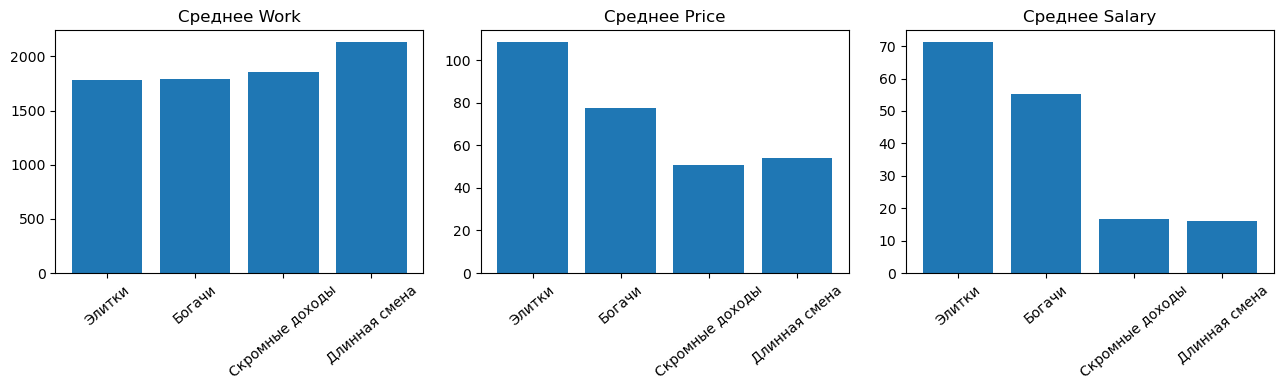

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
name_order = list(cluster_names.values())

for ax, column in zip(axes, numeric_columns):
    means = profile.set_index('Название').loc[name_order, column]
    ax.bar(name_order, means)
    ax.set_title(f'Среднее {column}')
    ax.tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.show()


На графиках ниже подписываю пограничные города. Это не типичные представители групп, а города на стыке двух соседних кластеров.

Между «Элитками» и «Богачами»: Stockholm, Copenhagen и Madrid. Между «Скромными доходами» и «Длинной сменой»: Buenos_Aires, Johannesburg, Mexico_City, Nairobi и Tel_Aviv.


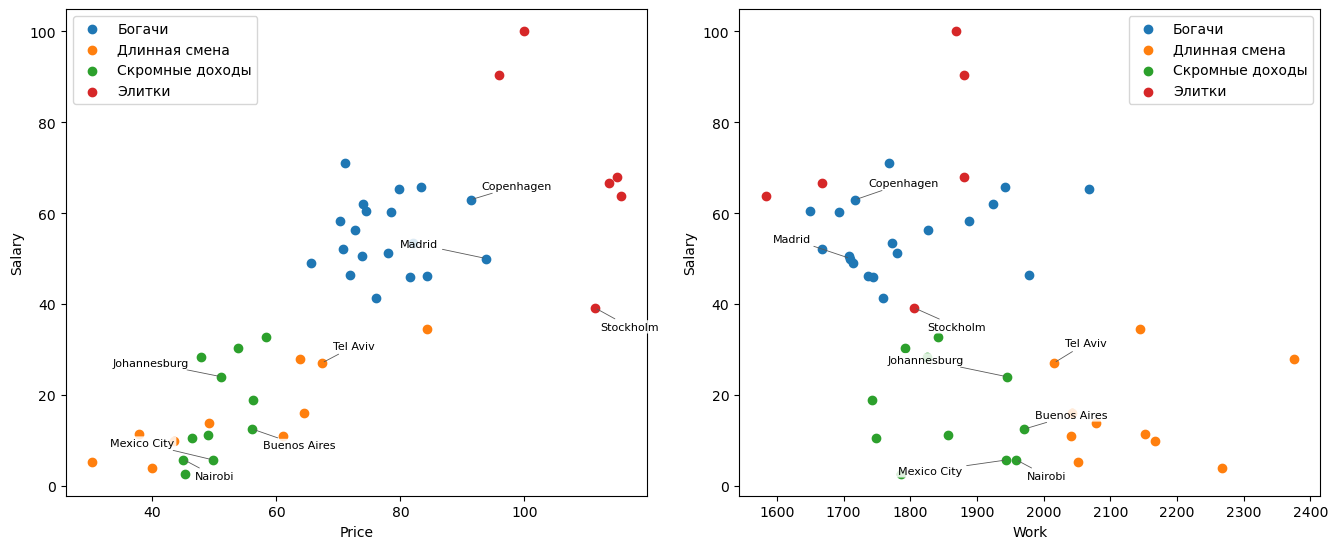

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))

for name, group in df_clusters.groupby('Название'):
    axes[0].scatter(group['Price'], group['Salary'], label=name, zorder=2)
    axes[1].scatter(group['Work'], group['Salary'], label=name, zorder=2)

border_cities = [
    'Stockholm', 'Copenhagen', 'Madrid',
    'Buenos_Aires', 'Johannesburg', 'Mexico_City', 'Nairobi', 'Tel_Aviv',
]
label_offsets = {
    'Price': {
        'Stockholm': (4, -16),
        'Copenhagen': (8, 8),
        'Madrid': (-62, 8),
        'Tel_Aviv': (8, 10),
        'Johannesburg': (-78, 8),
        'Buenos_Aires': (8, -14),
        'Mexico_City': (-74, 10),
        'Nairobi': (8, -14),
    },
    'Work': {
        'Stockholm': (10, -16),
        'Copenhagen': (10, 10),
        'Madrid': (-56, 12),
        'Tel_Aviv': (8, 12),
        'Johannesburg': (-86, 10),
        'Buenos_Aires': (8, 8),
        'Mexico_City': (-78, -10),
        'Nairobi': (8, -14),
    },
}
label_box = dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85)
label_arrow = dict(arrowstyle='-', color='0.35', lw=0.6)

for ax, x_col in ((axes[0], 'Price'), (axes[1], 'Work')):
    for city in border_cities:
        row = df_clusters.loc[city]
        ax.annotate(
            city.replace('_', ' '),
            (row[x_col], row['Salary']),
            textcoords='offset points',
            xytext=label_offsets[x_col][city],
            fontsize=8,
            bbox=label_box,
            arrowprops=label_arrow,
            zorder=3,
        )

axes[0].set_xlabel('Price')
axes[0].set_ylabel('Salary')
axes[0].legend(loc='upper left')

axes[1].set_xlabel('Work')
axes[1].set_ylabel('Salary')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


In [24]:
import plotly.express as px

plot_df = df_clusters.reset_index()
plot_df['Подпись'] = plot_df['City'].where(plot_df['City'].isin(border_cities), '')
plot_df['Подпись'] = plot_df['Подпись'].str.replace('_', ' ', regex=False)

fig_3d = px.scatter_3d(
    plot_df,
    x='Work',
    y='Price',
    z='Salary',
    color='Название',
    hover_name='City',
    text='Подпись',
    category_orders={'Название': name_order},
    title='Города по трем признакам, k-средних',
    height=650,
)
fig_3d.update_traces(marker_size=5, textposition='top center', textfont_size=11)
fig_3d.show()


Силуэт всего разбиения уже есть в таблице выше. Ниже силуэт отдельных городов: маленький или отрицательный значит, что город лежит между группами или на краю своей.


In [25]:
from sklearn.metrics import silhouette_samples

city_silhouette = pd.Series(
    silhouette_samples(X, df_clusters['Cluster']),
    index=df_clusters.index,
    name='Silhouette',
)
city_silhouette.nsmallest(6).round(3).to_frame()


,Silhouette
City,
Tel_Aviv,-0.029
Bombay,0.018
Stockholm,0.026
Caracas,0.081
Singpore,0.105
Taipei,0.156


Отдельно проверю границу между «Элитками» и «Богачами». Для каждого города из этих двух групп считаю расстояние до обоих центров в стандартизованных координатах.


In [26]:
centers = df_scaled.groupby(df_clusters['Cluster']).mean()
border_rows = []

for city in df_clusters.index[df_clusters['Cluster'].isin([1, 2])]:
    point = df_scaled.loc[city]
    distance_elite = np.linalg.norm(point - centers.loc[1])
    distance_rich = np.linalg.norm(point - centers.loc[2])
    border_rows.append({
        'City': city,
        'Кластер': cluster_names[int(df_clusters.loc[city, 'Cluster'])],
        'до Элиток': distance_elite,
        'до Богачей': distance_rich,
        'разница': abs(distance_elite - distance_rich),
    })

border = pd.DataFrame(border_rows).sort_values('разница')
border.head(8).round(2)


,City,Кластер,до Элиток,до Богачей,разница
3,Copenhagen,Богачи,0.96,0.84,0.11
13,Madrid,Богачи,1.19,0.93,0.26
19,Stockholm,Элитки,1.32,1.73,0.40
11,Los_Angeles,Богачи,2.17,1.66,0.51
16,New_York,Богачи,1.53,1.01,0.52
7,Geneva,Элитки,1.14,1.75,0.62
24,Zurich,Элитки,1.34,2.16,0.82
17,Oslo,Элитки,1.23,2.19,0.96


### Описание групп

1. **Элитки**, 6 городов: Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich. Самые высокие цены, в среднем `Price` 108.55, и самая высокая зарплата, `Salary` 71.30. Рабочих часов немного, около 1780. Отношение `Salary/Price` около 0.67: индекс зарплаты большой, но цены его частично съедают. Stockholm держится в этой группе в основном ценами (`Price` 111.3) при зарплате 39.2, поэтому у него почти нулевой силуэт.

2. **Богачи**, 19 городов: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna. Часов примерно столько же, цены и зарплаты ниже (77.53 и 55.16). `Salary/Price` около 0.72, это лучшее отношение из четырех групп. Copenhagen и Madrid ближе всех к границе с «Элитками»: у Copenhagen до своего центра 0.84, до центра «Элиток» 0.96.

3. **Скромные доходы**, 11 городов: Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul. `Salary` в среднем 16.59, `Price` 50.78. Рабочий день около 1855 часов, недалеко от богатых городов. Покупательная способность низкая, `Salary/Price` около 0.32. Самая низкая зарплата во всей таблице тоже здесь: у Lagos `Salary` 2.7.

4. **Длинная смена**, 10 городов: Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv. Зарплата почти такая же низкая, 16.08, а часов сильно больше, в среднем 2134. Hong Kong здесь крайняя точка по `Work`. У Bombay самая низкая цена во всей таблице, 30.3, и очень низкая зарплата, 5.3. Силуэт около нуля: город в своей группе, но на ее краю. У Tel_Aviv силуэт отрицательный, его `Work` 2015 лежит между средними третьей и четвертой групп, а `Price` и `Salary` выше, чем у обеих.

Обе нижние группы беднее двух верхних. Между собой они различаются прежде всего длиной рабочего дня, а не индексом зарплаты.

Пограничные города подписаны на графиках `Price`–`Salary`, `Work`–`Salary` и на 3D-картинке. Между верхними группами это Stockholm, Copenhagen и Madrid. Между двумя группами с низкой зарплатой это Buenos_Aires, Johannesburg, Mexico_City, Nairobi и Tel_Aviv.


## Этап 9. Сравнение с лабораторной 1

В первой работе иерархия строилась методом Уорда по тем же z-оценкам, разрез был на 4 кластера: «Элитки» (6), «Богачи» (19), «Бюджетные города» (7), «Работяги» (14). Повторю этот разрез здесь и приложу его к результату k-средних.

Для контроля построю еще полную связь. Уорд следит за ростом разброса внутри группы, полная связь смотрит на расстояние между самыми далекими точками двух групп. Если совсем разные правила дают похожие составы, разбиение не артефакт одного алгоритма.


In [27]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

distances = pdist(df_scaled, metric='euclidean')
Z_ward = linkage(distances, method='ward')
ward_labels = pd.Series(fcluster(Z_ward, t=4, criterion='maxclust'), index=df_clean.index)

print('Размеры групп Уорда:')
print(ward_labels.value_counts().sort_index().to_string())

ward_names = {
    1: 'Элитки (ЛР1)',
    2: 'Богачи (ЛР1)',
    3: 'Бюджетные (ЛР1)',
    4: 'Работяги (ЛР1)',
}
pd.crosstab(
    df_clusters['Название'],
    ward_labels.map(ward_names),
    rownames=['k-means'],
    colnames=['Уорд'],
)


Размеры групп Уорда:
1     6
2    19
3     7
4    14


Уорд,Богачи (ЛР1),Бюджетные (ЛР1),Работяги (ЛР1),Элитки (ЛР1)
k-means,,,,
Богачи,19,0,0,0
Длинная смена,0,0,10,0
Скромные доходы,0,7,4,0
Элитки,0,0,0,6


In [28]:
moved = df_clusters.index[(df_clusters['Cluster'] == 3) & (ward_labels == 4)]
print('В ЛР1 были среди «Работяг», k-means отнес к «Скромным доходам»:')
df_clean.loc[moved, numeric_columns].sort_values('Work')


В ЛР1 были среди «Работяг», k-means отнес к «Скромным доходам»:


,Work,Price,Salary
City,,,
Mexico_City,1944,49.8,5.7
Johannesburg,1945,51.1,24.0
Nairobi,1958,45.0,5.8
Buenos_Aires,1971,56.1,12.5


Проверю, ближе ли эти четыре города к центру «Скромных доходов» или к центру «Длинной смены». Рядом для ориентира ставлю Athens и Seoul, которые и раньше были в короткой группе, и Tel_Aviv с Hong Kong из длинной.


In [29]:
check_cities = [
    'Athens', 'Seoul',
    'Buenos_Aires', 'Johannesburg', 'Mexico_City', 'Nairobi',
    'Tel_Aviv', 'Hong_Kong',
]
distance_rows = []

for city in check_cities:
    point = df_scaled.loc[city]
    distance_rows.append({
        'City': city,
        'Кластер k-means': cluster_names[int(df_clusters.loc[city, 'Cluster'])],
        'Work': df_clean.loc[city, 'Work'],
        'до скромных': np.linalg.norm(point - centers.loc[3]),
        'до длинной смены': np.linalg.norm(point - centers.loc[4]),
    })

pd.DataFrame(distance_rows).set_index('City').round(2)


,Кластер k-means,Work,до скромных,до длинной смены
City,,,,
Athens,Скромные доходы,1792,0.69,2.07
Seoul,Скромные доходы,1842,0.75,1.83
Buenos_Aires,Скромные доходы,1971,0.73,0.96
Johannesburg,Скромные доходы,1945,0.60,1.15
Mexico_City,Скромные доходы,1944,0.68,1.20
Nairobi,Скромные доходы,1958,0.79,1.18
Tel_Aviv,Длинная смена,2015,1.28,1.03
Hong_Kong,Длинная смена,2375,3.11,1.55


In [30]:
Z_complete = linkage(distances, method='complete')
complete_labels = pd.Series(
    fcluster(Z_complete, t=4, criterion='maxclust'),
    index=df_clean.index,
)
pd.crosstab(
    df_clusters['Cluster'],
    complete_labels,
    rownames=['k-means'],
    colnames=['полная связь'],
)


полная связь,1,2,3,4
k-means,,,,
1,0,6,0,0
2,19,0,0,0
3,0,0,11,0
4,0,0,0,10


In [31]:
def within_ss(labels):
    total = 0.0
    labels = np.asarray(labels)
    for cluster in np.unique(labels):
        points = X[labels == cluster]
        total += ((points - points.mean(axis=0)) ** 2).sum()
    return total


comparison = pd.DataFrame({
    'J': [
        within_ss(df_clusters['Cluster']),
        within_ss(ward_labels),
        within_ss(complete_labels),
    ],
    'Silhouette': [
        silhouette_score(X, df_clusters['Cluster']),
        silhouette_score(X, ward_labels),
        silhouette_score(X, complete_labels),
    ],
}, index=['k-means', 'Уорд', 'полная связь'])
comparison.round(3)


,J,Silhouette
k-means,35.553,0.366
Уорд,36.501,0.355
полная связь,35.553,0.366


Размеры групп Уорда снова 6, 19, 7 и 14, как в первой работе. «Элитки» и «Богачи» у k-средних совпали с ними полностью. Расхождение только в четырех городах: Buenos_Aires, Johannesburg, Mexico_City и Nairobi. В лабораторной 1 они были в «Работягах», здесь попали в «Скромные доходы». На графиках этапа 8 они подписаны вместе с Tel_Aviv: эти пять городов лежат между двумя нижними группами.

По часам они как раз между средними двух нижних групп: `Work` от 1944 до 1971, при средних 1855 и 2134. До центра «Скромных доходов» каждому из них ближе, чем до центра «Длинной смены», поэтому k-средние оставляют их в третьей группе. Уорд перекладывать города не умеет: раз город уже приклеился к ветке с длинным днем, обратно он не уходит. Tel_Aviv при `Work` 2015 ближе к длинной смене, но оба расстояния у него около единицы, отсюда и отрицательный силуэт.

Таблица полной связи в каждой строке и каждом столбце содержит одно число. Составы групп совпали с k-средними, отличаются только номера. Поэтому и `J`, и силуэт у них одинаковые: `J` 35.55, силуэт 0.366. У Уорда `J` чуть хуже, 36.50, силуэт 0.355. Разница небольшая, то есть четыре спорных города не ломают общую картину, но по критерию k-средних новое разбиение плотнее.


## Этап 10. Выводы

Города сравнивал по `Work`, `Price` и `Salary` после z-стандартизации. Cairo и Jakarta в расчет не входили: у них известна только цена.

k-средние зависят от старта. Из 200 одиночных запусков лучшее `J` находилось реже чем в одном случае из десяти, и у случайных центров, и у k-means++. Неудачный старт склеил все города с высокой зарплатой в одну кучу и дал `J` около 44. Поэтому итог считал с k-means++ и 50 запусками. Получилось `J = 35.55`.

По величине скачка `J` и по силуэту (0.470) напрашиваются 2 кластера. Это слишком грубо, та же развилка была в первой работе. Беру **4 кластера**, силуэт 0.366. При трех кластерах не отделяются самые дорогие города, при пяти «Богачи» режутся по часам, и в длинную группу попадает Taipei с зарплатой 34.5. Силуэт на семи и восьми кластерах чуть выше, но группы уже мелкие.

Итог:

1. **Элитки** (6): Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich. Самые высокие цены и зарплаты, `Salary/Price` около 0.67.
2. **Богачи** (19): города Европы и Северной Америки и Sydney. Часов столько же, цены и зарплаты ниже, `Salary/Price` около 0.72, лучшее из четырех.
3. **Скромные доходы** (11): низкие цены и зарплаты при рабочем дне около 1855 часов.
4. **Длинная смена** (10): такая же низкая зарплата и заметно больше рабочих часов, в среднем 2134. Здесь же Hong Kong.

С методом Уорда из первой работы совпали верхние две группы. Buenos_Aires, Johannesburg, Mexico_City и Nairobi перешли из «Работяг» в «Скромные доходы»: по часам они между двумя нижними центрами и ближе к более короткому. Полная связь дала те же составы, что и k-средние, так что четверка групп держится не на одном алгоритме.

Границы мягкие, пограничные города подписаны на графиках. Между «Элитками» и «Богачами» это Stockholm, Copenhagen и Madrid: у Copenhagen расстояния до двух центров почти равны, а Stockholm держится в «Элитках» в основном из-за цен. Между «Скромными доходами» и «Длинной сменой» это Buenos_Aires, Johannesburg, Mexico_City, Nairobi и Tel_Aviv. Tel_Aviv формально в «Длинной смене», но силуэт у него отрицательный.
